In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy, AUC
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import random

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\python\keras\engine\training_arrays_v1.py:37: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 1.23.2)
  from scipy.sparse import issparse  # pylint: disable=g-import-not-at-top


In [2]:
# Set seed for reproducibility
seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

In [3]:
# Load the dataset
data_x = pd.read_csv('X_cma.csv')
data_y = pd.read_csv('y_cma.csv')

In [4]:
# Remove the 'Unnamed: 0' column if it exists
if 'Unnamed: 0' in data_x.columns:
    data_x = data_x.drop(columns=['Unnamed: 0'])
if 'Unnamed: 0' in data_y.columns:
    data_y = data_y.drop(columns=['Unnamed: 0'])

In [5]:
# Feature selection
columns_to_keep = list(data_x.columns[:6]) + [
    'EMA_25_mkt', 'SMA_100_cma', 'EMA_26_rmw', 'EMA_25_smb',
    'EMA_25_umd', 'EMA_12_cma', 'RSI_9_cma', 'EMA_26_hml',
    'RSI_9_rmw', 'RSI_9_mkt', 'RSI_9_smb', 'RSI_14_hml'
]

X_train = data_x[columns_to_keep]
y_train = data_y['Target']

In [6]:
# Convert to numpy arrays
X = X_train.values
y = y_train.values

In [7]:
# Use StandardScaler to scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [8]:
# Convert back to DataFrame for EDA
X_scaled_df = pd.DataFrame(X_scaled, columns=columns_to_keep)

In [9]:
# Perform EDA on the final input matrix
X_scaled_df.describe().T

,count,mean,std,min,25%,50%,75%,max
RET_cma,2129.0,-8.760802e-18,1.000235,-8.293726,-0.517883,-0.006036,0.525959,7.933323
RET_hml,2129.0,6.674897e-18,1.000235,-3.887676,-0.611578,-0.033145,0.587042,4.753445
RET_mkt,2129.0,2.336214e-17,1.000235,-11.363081,-0.448243,0.018535,0.479991,8.588009
RET_rmw,2129.0,1.168107e-17,1.000235,-5.501667,-0.596083,0.006557,0.610159,5.115630
RET_smb,2129.0,0.000000e+00,1.000235,-8.440059,-0.494293,0.030894,0.573561,6.091110
RET_umd,2129.0,-2.085905e-18,1.000235,-13.256709,-0.516088,-0.003167,0.519158,7.499463
EMA_25_mkt,2129.0,1.174782e-15,1.000235,-2.292113,-0.798175,0.276070,0.832795,1.495881
SMA_100_cma,2129.0,7.475884e-16,1.000235,-1.276413,-0.977475,-0.305629,0.709515,2.710751
EMA_26_rmw,2129.0,-1.922370e-15,1.000235,-2.421149,-0.617095,-0.129423,0.472417,3.368184
EMA_25_smb,2129.0,-8.009876e-17,1.000235,-1.976555,-0.907582,0.492530,0.805121,1.280829


In [10]:
# Define custom class weight function
def cwts(dfs):
    c0, c1 = np.bincount(dfs)
    w0 = (1 / c0) * (len(dfs)) / 2
    w1 = (1 / c1) * (len(dfs)) / 2
    return {0: w0, 1: w1}


In [11]:
# Define sliding window parameters
window_size = 600
step_size = 1

In [12]:
# Determine the start point to process only the last 500 windows
start_point = len(X) - (500 * step_size) - window_size

In [13]:
# Lists to store results
all_test_predictions = []
all_actual_test_values = []
all_prediction_probabilities = []
all_predicted_classes = []
all_predicted_probabilities = []

In [14]:
# Define model creation function
def create_model(hu=20, lookback=10, features=1):
    tf.keras.backend.clear_session()
    model = Sequential()
    model.add(LSTM(units=hu, input_shape=(lookback, features), activation='relu', return_sequences=False, name='LSTM1'))
    model.add(Dropout(0.4, name='Dropout1'))
    model.add(Dense(units=1, activation='sigmoid', name='Output'))
    opt = Adam(learning_rate=0.001, epsilon=1e-08, decay=0.0)
    model.compile(optimizer=opt, 
                  loss=BinaryCrossentropy(), 
                  metrics=[BinaryAccuracy(name='accuracy', threshold=0.5), AUC()])
    return model

In [15]:
# EarlyStopping and ReduceLROnPlateau callbacks
early_stopping = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='loss', factor=0.2, patience=5, min_lr=0.0001)



Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5780 - auc: 0.3380 - loss: 0.7027 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7363 - auc: 0.5189 - loss: 0.6065 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9219 - auc: 0.0000e+00 - loss: 0.4908

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7906 - auc: 0.5764 - loss: 0.5585 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8596 - auc: 0.6588 - loss: 0.4876 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8758 - auc: 0.6788 - loss: 0.4216 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9009 - auc: 0.6906 - loss: 0.3676 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9385 - auc: 0.7100 - loss: 0.2841 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9479 - auc: 0.7140 - loss: 0.2083 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9579 - auc: 0.7203 - loss: 0.1481 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9770 - auc: 0.7243 - loss: 0.0872 - learning_rate: 0.0010
Epoch 11/74
10/10 ━━━━━━━━━━━━━━━━

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


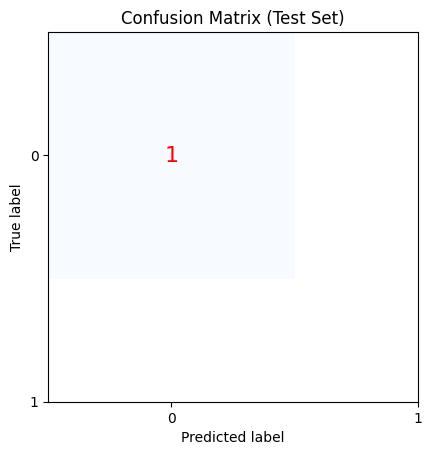

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4050 - auc: 0.2526 - loss: 0.7868 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6292 - auc: 0.4346 - loss: 0.6592 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7812 - auc: 0.0000e+00 - loss: 0.5835

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6658 - auc: 0.5024 - loss: 0.6191 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7450 - auc: 0.5770 - loss: 0.5547 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8009 - auc: 0.6241 - loss: 0.5008 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8370 - auc: 0.6777 - loss: 0.4156 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8853 - auc: 0.6962 - loss: 0.3592 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9263 - auc: 0.7127 - loss: 0.2591 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9522 - auc: 0.7197 - loss: 0.1710 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9661 - auc: 0.7229 - loss: 0.1290 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


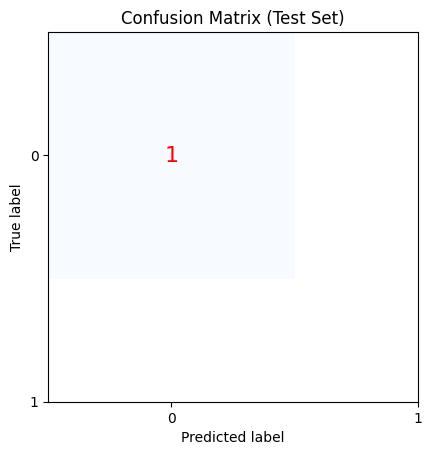

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7613 - auc: 0.5928 - loss: 0.5742 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8376 - auc: 0.6607 - loss: 0.4924 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8927 - auc: 0.6834 - loss: 0.4447 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9179 - auc: 0.7041 - loss: 0.3793 - learning_rate: 0.0010
Epoch 5/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9293 - auc: 0.7081 - loss: 0.3248 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9408 - auc: 0.7132 - loss: 0.2626 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9532 - auc: 0.7192 - loss: 0.2069 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9757 - auc: 0.7222 - loss: 0.1508 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9731 - auc: 0.7225 - loss: 0.1034 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9774 - auc: 0.7240 - loss: 0.0760 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Test Prediction: 0.49 (Class: 0)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


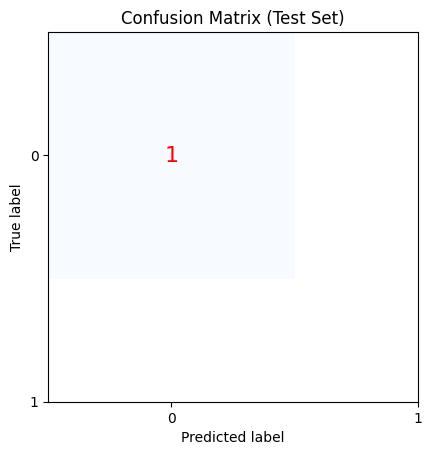

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.2670 - auc: 0.1289 - loss: 1.0636 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3647 - auc: 0.2186 - loss: 0.8897 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5053 - auc: 0.3347 - loss: 0.7699 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5792 - auc: 0.4467 - loss: 0.6912 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6865 - auc: 0.5568 - loss: 0.6194 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7827 - auc: 0.6272 - loss: 0.5446 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8705 - auc: 0.6626 - loss: 0.4737 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9109 - auc: 0.7016 - loss: 0.4039 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9495 - auc: 0.7155 - loss: 0.3054 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9544 - auc: 0.7202 - loss: 0.2135 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
Test Prediction: 0.43 (Class: 0)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


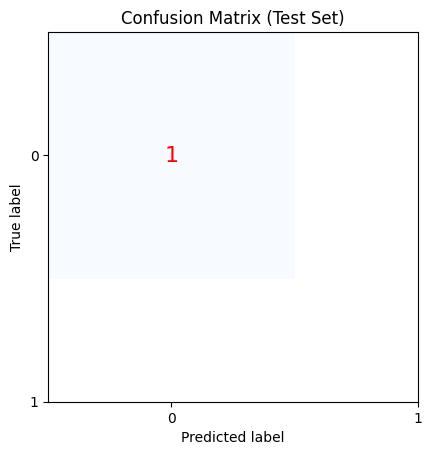

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7270 - auc: 0.6184 - loss: 0.6172 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8807 - auc: 0.6717 - loss: 0.4993 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8881 - auc: 0.6945 - loss: 0.4152 - learning_rate: 0.0010
Epoch 4/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 1.0000 - auc: 0.0000e+00 - loss: 0.2442

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9443 - auc: 0.7121 - loss: 0.3177 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9400 - auc: 0.7145 - loss: 0.2352 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9670 - auc: 0.7211 - loss: 0.1595 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9699 - auc: 0.7238 - loss: 0.1013 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9789 - auc: 0.7242 - loss: 0.0783 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9803 - auc: 0.7256 - loss: 0.0564 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9864 - auc: 0.7259 - loss: 0.0466 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
Test Prediction: 0.43 (Class: 0)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


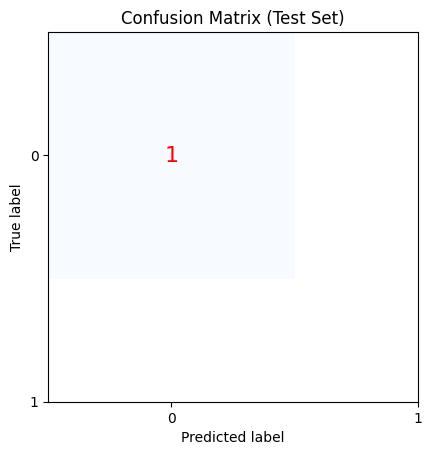

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7337 - auc: 0.5504 - loss: 0.6212 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8878 - auc: 0.6564 - loss: 0.5287 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8727 - auc: 0.6666 - loss: 0.5043 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8868 - auc: 0.6893 - loss: 0.4486 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9232 - auc: 0.7106 - loss: 0.3718 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9465 - auc: 0.7167 - loss: 0.3327 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9627 - auc: 0.7210 - loss: 0.2453 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9796 - auc: 0.7237 - loss: 0.2051 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9716 - auc: 0.7243 - loss: 0.1470 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9870 - auc: 0.7259 - loss: 0.0993 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Test Prediction: 0.50 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


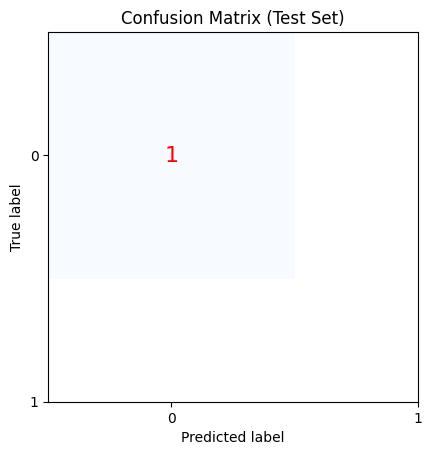

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6827 - auc: 0.4485 - loss: 0.6703 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7928 - auc: 0.5770 - loss: 0.5659 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8613 - auc: 0.6325 - loss: 0.5074 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8778 - auc: 0.6646 - loss: 0.4422 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9106 - auc: 0.6787 - loss: 0.3979 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9317 - auc: 0.7069 - loss: 0.3164 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9480 - auc: 0.7154 - loss: 0.2468 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9463 - auc: 0.7201 - loss: 0.1781 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9686 - auc: 0.7238 - loss: 0.1139 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9806 - auc: 0.7253 - loss: 0.0782 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
Test Prediction: 0.39 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


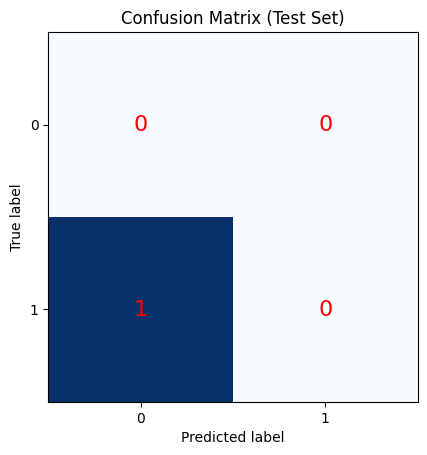

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5686 - auc: 0.3829 - loss: 0.7270 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7933 - auc: 0.5601 - loss: 0.5710 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8443 - auc: 0.6172 - loss: 0.5070 - learning_rate: 0.0010
Epoch 4/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9688 - auc: 0.0000e+00 - loss: 0.3976

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8917 - auc: 0.6745 - loss: 0.4203 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9149 - auc: 0.6970 - loss: 0.3239 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9341 - auc: 0.7093 - loss: 0.2445 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9425 - auc: 0.7141 - loss: 0.1685 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9474 - auc: 0.7180 - loss: 0.1238 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9629 - auc: 0.7206 - loss: 0.0824 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9759 - auc: 0.7223 - loss: 0.0726 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
Test Prediction: 0.49 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


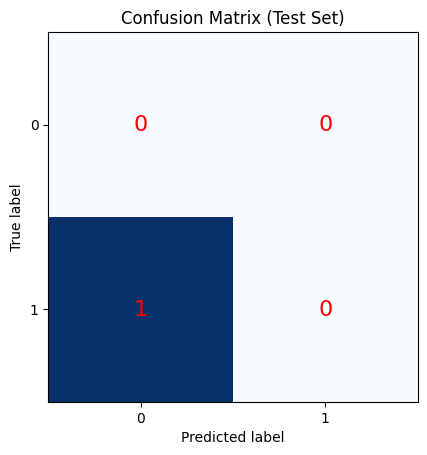

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4217 - auc: 0.5091 - loss: 0.7632 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5825 - auc: 0.5992 - loss: 0.6513 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7184 - auc: 0.6660 - loss: 0.5598 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7852 - auc: 0.6846 - loss: 0.5101 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9007 - auc: 0.7042 - loss: 0.4236 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9414 - auc: 0.7112 - loss: 0.3528 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9485 - auc: 0.7178 - loss: 0.2449 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9659 - auc: 0.7219 - loss: 0.1882 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9745 - auc: 0.7234 - loss: 0.1146 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9778 - auc: 0.7239 - loss: 0.0845 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
Test Prediction: 0.51 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


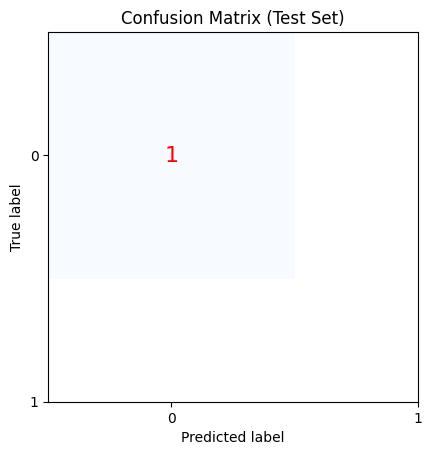

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4087 - auc: 0.2437 - loss: 0.8405 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5595 - auc: 0.4266 - loss: 0.7218 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6426 - auc: 0.5067 - loss: 0.6669 - learning_rate: 0.0010


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7563 - auc: 0.6217 - loss: 0.5740 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8296 - auc: 0.6661 - loss: 0.5066 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8731 - auc: 0.6859 - loss: 0.4467 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9111 - auc: 0.7027 - loss: 0.3606 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9389 - auc: 0.7158 - loss: 0.2833 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9306 - auc: 0.7137 - loss: 0.2126 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9621 - auc: 0.7212 - loss: 0.1367 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
Test Prediction: 0.50 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


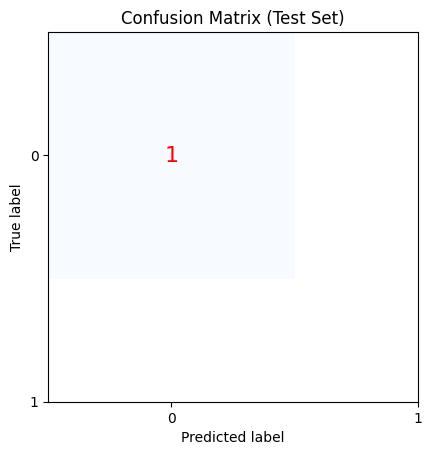

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4326 - auc: 0.5208 - loss: 0.8041 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6682 - auc: 0.6216 - loss: 0.6572 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8438 - auc: 0.0000e+00 - loss: 0.6303

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7781 - auc: 0.6652 - loss: 0.5688 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8673 - auc: 0.6975 - loss: 0.4755 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9084 - auc: 0.7115 - loss: 0.3867 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9453 - auc: 0.7148 - loss: 0.3081 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9540 - auc: 0.7171 - loss: 0.2232 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9678 - auc: 0.7221 - loss: 0.1662 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9839 - auc: 0.7245 - loss: 0.1220 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9831 - auc: 0.7238 - loss: 0.0962 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/

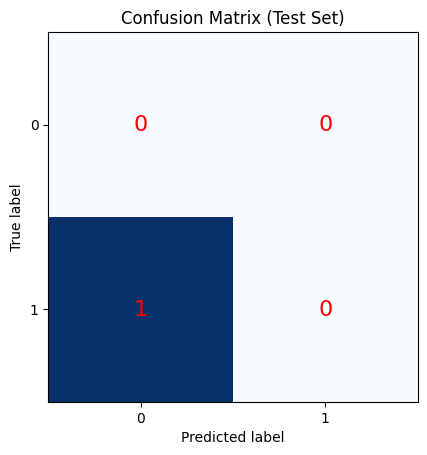

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5888 - auc: 0.3802 - loss: 0.6853 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7123 - auc: 0.5216 - loss: 0.5912 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9219 - auc: 0.0000e+00 - loss: 0.4284

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7798 - auc: 0.5969 - loss: 0.5150 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8243 - auc: 0.6443 - loss: 0.4740 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8875 - auc: 0.6846 - loss: 0.3758 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9071 - auc: 0.7026 - loss: 0.2906 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9263 - auc: 0.7138 - loss: 0.2151 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9710 - auc: 0.7226 - loss: 0.1401 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9704 - auc: 0.7239 - loss: 0.1018 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9710 - auc: 0.7234 - loss: 0.0864 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/

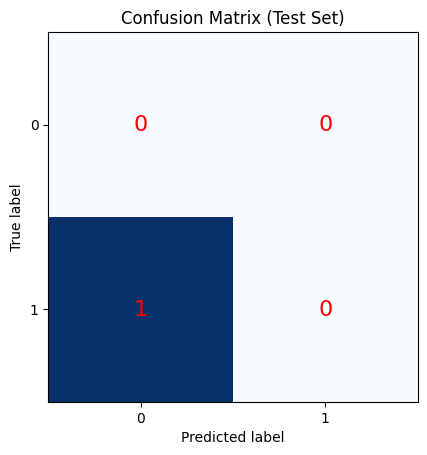

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4730 - auc: 0.3477 - loss: 0.8739 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5024 - auc: 0.4144 - loss: 0.7720 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6423 - auc: 0.5402 - loss: 0.6319 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7569 - auc: 0.6069 - loss: 0.5555 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8007 - auc: 0.6603 - loss: 0.4642 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8754 - auc: 0.6866 - loss: 0.3908 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9228 - auc: 0.7066 - loss: 0.3044 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9432 - auc: 0.7173 - loss: 0.2074 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9534 - auc: 0.7181 - loss: 0.1549 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9731 - auc: 0.7240 - loss: 0.1048 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
Test Prediction: 0.51 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


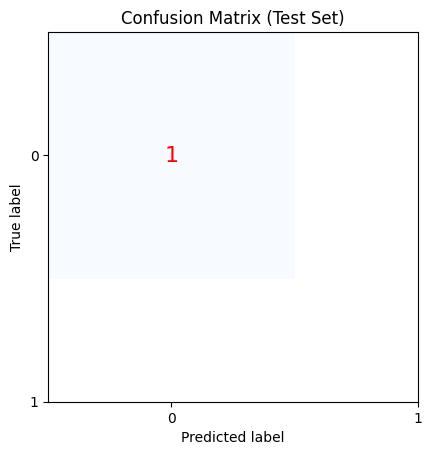

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7753 - auc: 0.6211 - loss: 0.5010 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8804 - auc: 0.6737 - loss: 0.3867 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8913 - auc: 0.6934 - loss: 0.3140 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9294 - auc: 0.7070 - loss: 0.2510 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9515 - auc: 0.7133 - loss: 0.2009 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9682 - auc: 0.7183 - loss: 0.1480 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9731 - auc: 0.7231 - loss: 0.1139 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9858 - auc: 0.7224 - loss: 0.0820 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9805 - auc: 0.7232 - loss: 0.0764 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9843 - auc: 0.7229 - loss: 0.0635 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
Test Prediction: 0.52 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


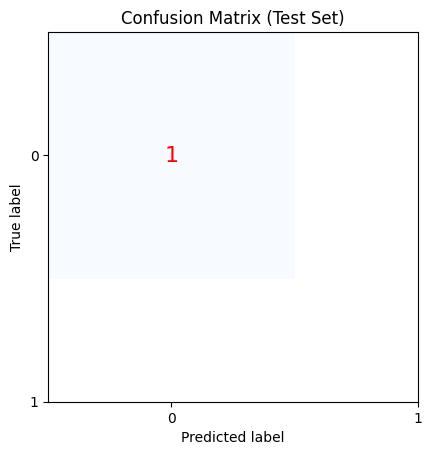

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6334 - auc: 0.5928 - loss: 0.6681 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7760 - auc: 0.6481 - loss: 0.5931 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8281 - auc: 0.6815 - loss: 0.5133 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9164 - auc: 0.7079 - loss: 0.4221 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9358 - auc: 0.7151 - loss: 0.3486 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9236 - auc: 0.7138 - loss: 0.2639 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9656 - auc: 0.7192 - loss: 0.1912 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9633 - auc: 0.7198 - loss: 0.1463 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9652 - auc: 0.7227 - loss: 0.1140 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9699 - auc: 0.7225 - loss: 0.0834 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
Test Prediction: 0.51 (Class: 1)
Confusion Matrix:
[[0 1]
 [0 0]]
TN: 0, FP: 1, FN: 0, TP: 0


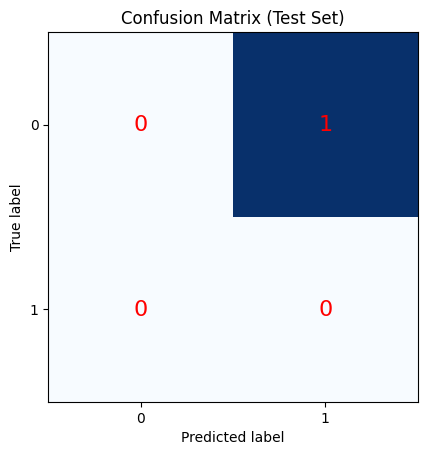

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4751 - auc: 0.4184 - loss: 0.7960 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5776 - auc: 0.5379 - loss: 0.7071 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6973 - auc: 0.6360 - loss: 0.6311 - learning_rate: 0.0010
Epoch 4/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5312 - auc: 0.0000e+00 - loss: 0.7737

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7761 - auc: 0.6733 - loss: 0.5681 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8445 - auc: 0.6995 - loss: 0.5153 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8859 - auc: 0.7098 - loss: 0.4450 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9198 - auc: 0.7152 - loss: 0.3706 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9591 - auc: 0.7230 - loss: 0.2712 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9767 - auc: 0.7241 - loss: 0.1971 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9761 - auc: 0.7222 - loss: 0.1246 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Test Prediction: 0.50 (Class: 1)
Confusion Matrix:
[[0 1]
 [0 0]]
TN: 0, FP: 1, FN: 0, TP: 0


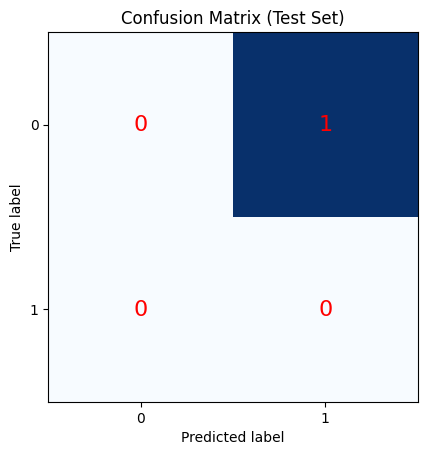

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6197 - auc: 0.2651 - loss: 0.7553 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6757 - auc: 0.4472 - loss: 0.6252 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9531 - auc: 0.0000e+00 - loss: 0.4228

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7098 - auc: 0.5267 - loss: 0.5746 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7836 - auc: 0.6031 - loss: 0.5046 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8486 - auc: 0.6677 - loss: 0.4391 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8792 - auc: 0.6805 - loss: 0.3731 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8842 - auc: 0.6835 - loss: 0.3386 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9268 - auc: 0.7042 - loss: 0.2537 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9254 - auc: 0.7105 - loss: 0.2108 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9375 - auc: 0.7114 - loss: 0.1671 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


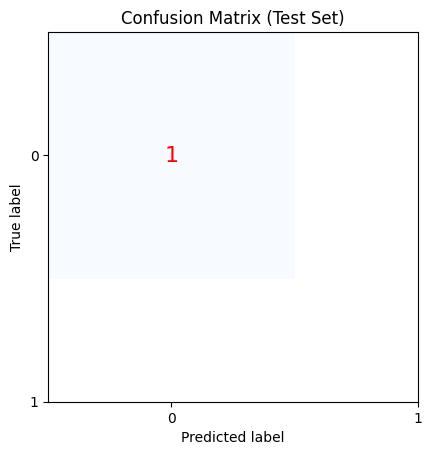

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3440 - auc: 0.2854 - loss: 0.8744 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5076 - auc: 0.4447 - loss: 0.7394 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6647 - auc: 0.5465 - loss: 0.6448 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7143 - auc: 0.5996 - loss: 0.5943 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8068 - auc: 0.6567 - loss: 0.5198 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8423 - auc: 0.6851 - loss: 0.4697 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8708 - auc: 0.6969 - loss: 0.4190 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9131 - auc: 0.7076 - loss: 0.3622 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9318 - auc: 0.7128 - loss: 0.3037 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9533 - auc: 0.7179 - loss: 0.2386 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
Test Prediction: 0.49 (Class: 0)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


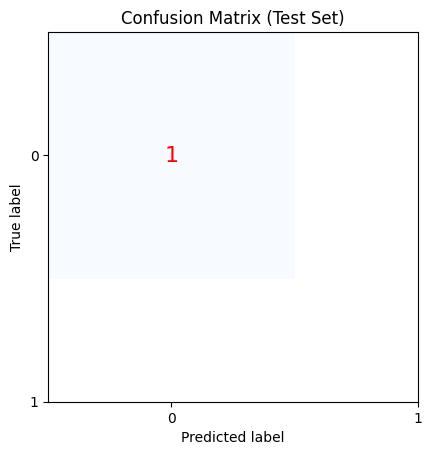

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5939 - auc: 0.4327 - loss: 0.6845 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7467 - auc: 0.5727 - loss: 0.6053 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8207 - auc: 0.6298 - loss: 0.5637 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8587 - auc: 0.6655 - loss: 0.5298 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8857 - auc: 0.6864 - loss: 0.4848 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9220 - auc: 0.7098 - loss: 0.4176 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9414 - auc: 0.7121 - loss: 0.3529 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9495 - auc: 0.7201 - loss: 0.3142 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9642 - auc: 0.7218 - loss: 0.2659 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9649 - auc: 0.7244 - loss: 0.2061 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
Test Prediction: 0.53 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


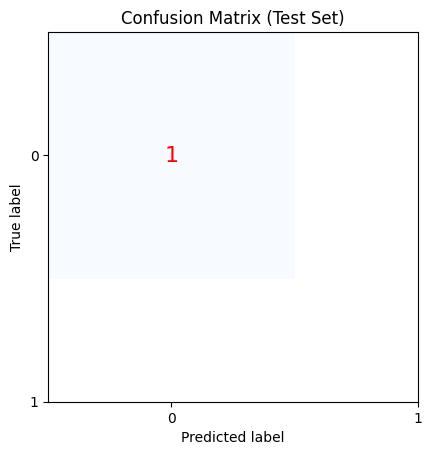

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4697 - auc: 0.3913 - loss: 0.7636 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7304 - auc: 0.5705 - loss: 0.6053 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8218 - auc: 0.6540 - loss: 0.4936 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8965 - auc: 0.6850 - loss: 0.4061 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9245 - auc: 0.7072 - loss: 0.3176 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9341 - auc: 0.7118 - loss: 0.2382 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9456 - auc: 0.7154 - loss: 0.1811 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9683 - auc: 0.7223 - loss: 0.1199 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9680 - auc: 0.7228 - loss: 0.0904 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9685 - auc: 0.7231 - loss: 0.0814 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
Test Prediction: 0.50 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


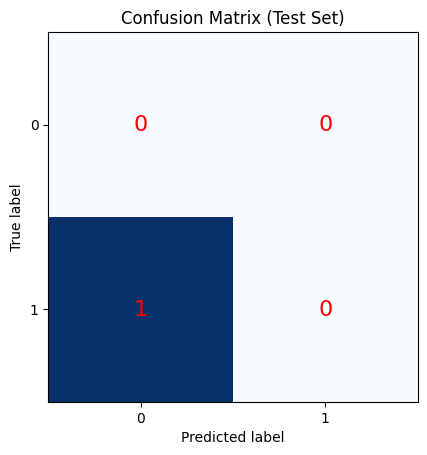

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3350 - auc: 0.2342 - loss: 0.8832 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5341 - auc: 0.4433 - loss: 0.7302 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6526 - auc: 0.5346 - loss: 0.6708 - learning_rate: 0.0010


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7755 - auc: 0.6484 - loss: 0.5610 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8445 - auc: 0.6782 - loss: 0.5029 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8994 - auc: 0.7039 - loss: 0.4080 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9371 - auc: 0.7099 - loss: 0.3186 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9646 - auc: 0.7200 - loss: 0.2033 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9546 - auc: 0.7183 - loss: 0.1439 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9561 - auc: 0.7207 - loss: 0.1008 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
Test Prediction: 0.54 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


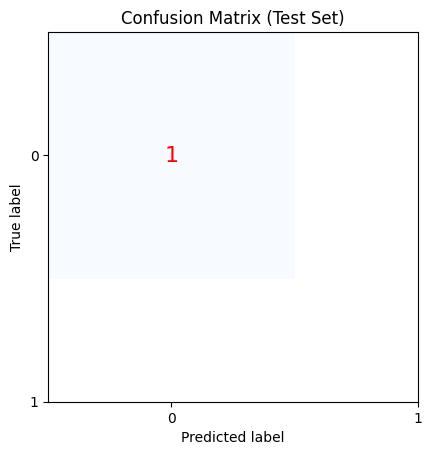

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5492 - auc: 0.5086 - loss: 0.7217 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7227 - auc: 0.6110 - loss: 0.6539 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7720 - auc: 0.6663 - loss: 0.6110 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8573 - auc: 0.6898 - loss: 0.5694 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8465 - auc: 0.6911 - loss: 0.5324 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8820 - auc: 0.7040 - loss: 0.4776 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9224 - auc: 0.7143 - loss: 0.4009 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9052 - auc: 0.7166 - loss: 0.3410 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9522 - auc: 0.7213 - loss: 0.2225 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9409 - auc: 0.7200 - loss: 0.1565 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
Test Prediction: 0.53 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


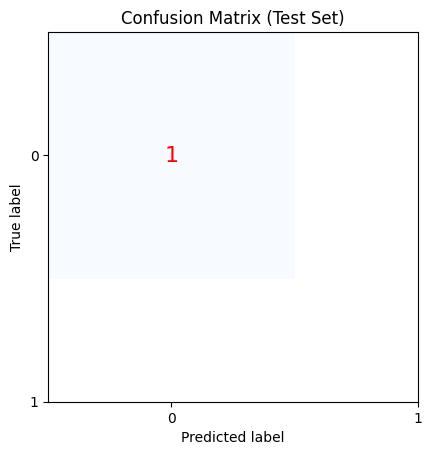

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4854 - auc: 0.3692 - loss: 0.7649 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6322 - auc: 0.5596 - loss: 0.6692 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7252 - auc: 0.6278 - loss: 0.6169 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8259 - auc: 0.7230 - loss: 0.5208 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8616 - auc: 0.7707 - loss: 0.4728 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8765 - auc: 0.7498 - loss: 0.4015 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9251 - auc: 0.7802 - loss: 0.3364 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9217 - auc: 0.8048 - loss: 0.2516 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9478 - auc: 0.8100 - loss: 0.1783 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9569 - auc: 0.8003 - loss: 0.1424 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Test Prediction: 0.50 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


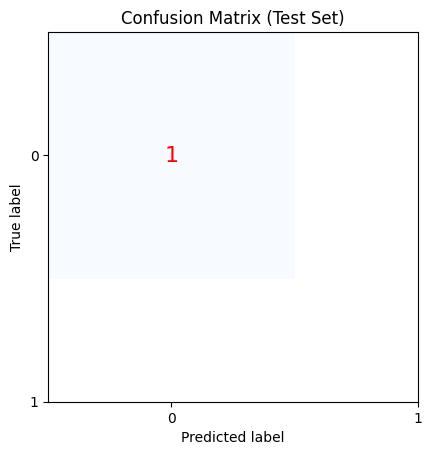

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6387 - auc: 0.5167 - loss: 0.6827 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7708 - auc: 0.6377 - loss: 0.6020 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8378 - auc: 0.7213 - loss: 0.5452 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8594 - auc: 0.7047 - loss: 0.4941 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9222 - auc: 0.7683 - loss: 0.4381 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9221 - auc: 0.7945 - loss: 0.3686 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9372 - auc: 0.7960 - loss: 0.3157 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9528 - auc: 0.8059 - loss: 0.2318 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9602 - auc: 0.8092 - loss: 0.1749 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9591 - auc: 0.8083 - loss: 0.1341 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
Test Prediction: 0.52 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


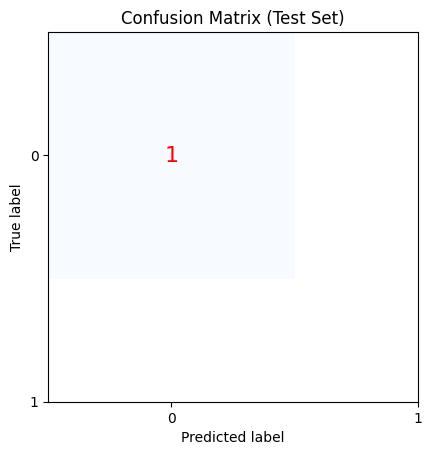

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3855 - auc: 0.5672 - loss: 0.9407 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4207 - auc: 0.6421 - loss: 0.8198 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4923 - auc: 0.7037 - loss: 0.7200 - learning_rate: 0.0010
Epoch 4/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4062 - auc: 0.0000e+00 - loss: 0.8537

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5970 - auc: 0.7470 - loss: 0.6405 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7255 - auc: 0.7980 - loss: 0.5550 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8005 - auc: 0.7857 - loss: 0.5022 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8684 - auc: 0.7978 - loss: 0.4233 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9180 - auc: 0.8042 - loss: 0.3543 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9298 - auc: 0.8058 - loss: 0.2698 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9590 - auc: 0.8108 - loss: 0.1976 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
Test Prediction: 0.56 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


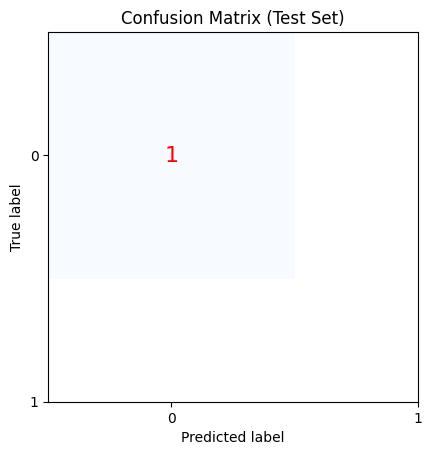

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6514 - auc: 0.5161 - loss: 0.6516 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7123 - auc: 0.6203 - loss: 0.5707 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7634 - auc: 0.6751 - loss: 0.5252 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7817 - auc: 0.7346 - loss: 0.4683 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8339 - auc: 0.7392 - loss: 0.4243 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8629 - auc: 0.7592 - loss: 0.3623 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9040 - auc: 0.7837 - loss: 0.2836 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9130 - auc: 0.7950 - loss: 0.2203 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9485 - auc: 0.8083 - loss: 0.1712 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9499 - auc: 0.8104 - loss: 0.1303 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
Test Prediction: 0.48 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


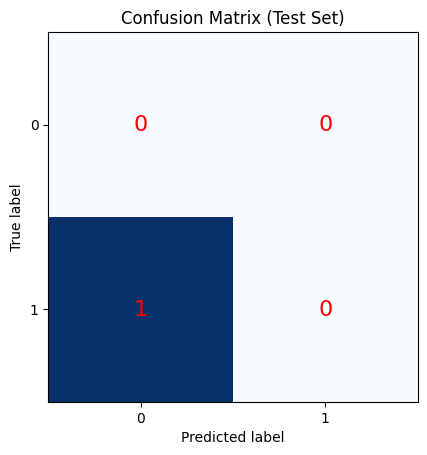

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4823 - auc: 0.3695 - loss: 0.7652 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5913 - auc: 0.5160 - loss: 0.6663 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9219 - auc: 0.0000e+00 - loss: 0.5674

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6765 - auc: 0.5985 - loss: 0.6046 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7547 - auc: 0.6988 - loss: 0.5402 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8122 - auc: 0.7518 - loss: 0.4966 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8553 - auc: 0.7797 - loss: 0.4354 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9034 - auc: 0.7687 - loss: 0.3690 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9190 - auc: 0.8022 - loss: 0.2903 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9284 - auc: 0.7970 - loss: 0.2311 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9305 - auc: 0.7851 - loss: 0.1806 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/

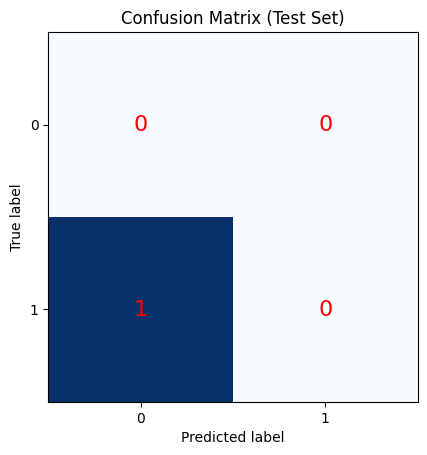

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6366 - auc: 0.4588 - loss: 0.6723 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7454 - auc: 0.5915 - loss: 0.5723 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7807 - auc: 0.6398 - loss: 0.5161 - learning_rate: 0.0010
Epoch 4/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9844 - auc: 0.0000e+00 - loss: 0.4163

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8539 - auc: 0.7168 - loss: 0.4466 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8900 - auc: 0.7533 - loss: 0.3828 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9191 - auc: 0.7825 - loss: 0.3328 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9326 - auc: 0.7990 - loss: 0.2790 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9459 - auc: 0.8042 - loss: 0.2364 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9396 - auc: 0.7992 - loss: 0.1852 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9408 - auc: 0.8002 - loss: 0.1560 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
Test Prediction: 0.56 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


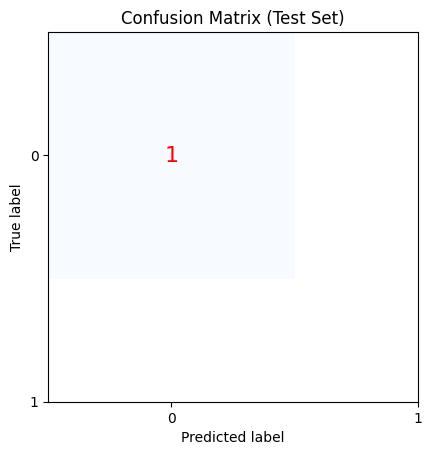

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5454 - auc: 0.2403 - loss: 0.8485 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6410 - auc: 0.3262 - loss: 0.7175 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6915 - auc: 0.5232 - loss: 0.6340 - learning_rate: 0.0010


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7204 - auc: 0.5908 - loss: 0.5866 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7848 - auc: 0.6865 - loss: 0.5307 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8582 - auc: 0.7435 - loss: 0.4720 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8763 - auc: 0.7457 - loss: 0.4318 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8926 - auc: 0.7357 - loss: 0.3771 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9216 - auc: 0.7946 - loss: 0.2955 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9313 - auc: 0.7733 - loss: 0.2402 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
Test Prediction: 0.47 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


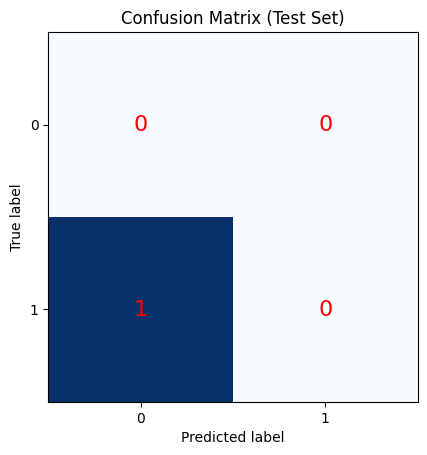

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3454 - auc: 0.2903 - loss: 1.0872 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3708 - auc: 0.3561 - loss: 0.9294 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4425 - auc: 0.4467 - loss: 0.8263 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5215 - auc: 0.5148 - loss: 0.7350 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6563 - auc: 0.6307 - loss: 0.6612 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7234 - auc: 0.6611 - loss: 0.5868 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7788 - auc: 0.7470 - loss: 0.5136 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8808 - auc: 0.7820 - loss: 0.4088 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9063 - auc: 0.7923 - loss: 0.3162 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9305 - auc: 0.8005 - loss: 0.2469 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Test Prediction: 0.51 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


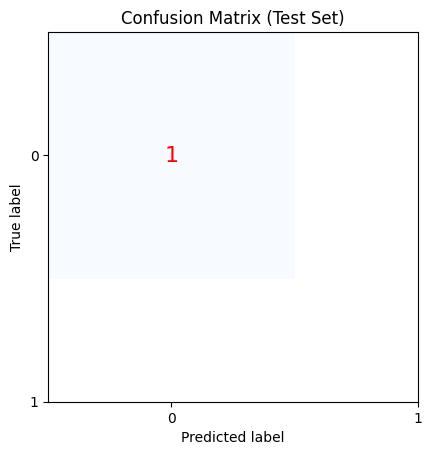

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4421 - auc: 0.3820 - loss: 0.8436 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5855 - auc: 0.5630 - loss: 0.7045 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6878 - auc: 0.6535 - loss: 0.5920 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7389 - auc: 0.7156 - loss: 0.5464 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8249 - auc: 0.7288 - loss: 0.4706 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9009 - auc: 0.7802 - loss: 0.3972 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9072 - auc: 0.7979 - loss: 0.3673 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9428 - auc: 0.8047 - loss: 0.2856 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9445 - auc: 0.8085 - loss: 0.2163 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9581 - auc: 0.8100 - loss: 0.1661 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
Test Prediction: 0.50 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


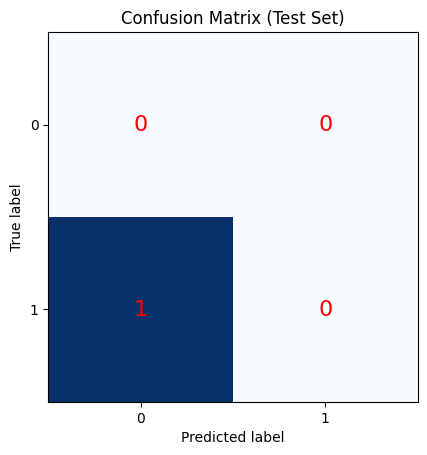

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3925 - auc: 0.2825 - loss: 0.8406 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5516 - auc: 0.4642 - loss: 0.7235 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6473 - auc: 0.5110 - loss: 0.6666 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7408 - auc: 0.6188 - loss: 0.6016 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8149 - auc: 0.7283 - loss: 0.5234 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8432 - auc: 0.7464 - loss: 0.4669 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8944 - auc: 0.7639 - loss: 0.3867 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9246 - auc: 0.7902 - loss: 0.3024 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9396 - auc: 0.7871 - loss: 0.2248 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9457 - auc: 0.8056 - loss: 0.1864 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
Test Prediction: 0.51 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


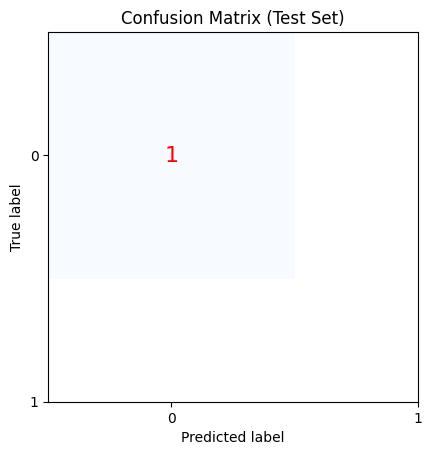

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1960 - auc: 0.1198 - loss: 1.1265 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2929 - auc: 0.2092 - loss: 0.9557 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.1562 - auc: 0.0000e+00 - loss: 1.0778

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3910 - auc: 0.4084 - loss: 0.8539 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4093 - auc: 0.4017 - loss: 0.8262 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4947 - auc: 0.5352 - loss: 0.7652 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5370 - auc: 0.6120 - loss: 0.7207 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6412 - auc: 0.6730 - loss: 0.6637 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6895 - auc: 0.7338 - loss: 0.6139 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7724 - auc: 0.7492 - loss: 0.5512 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8103 - auc: 0.7716 - loss: 0.5031 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/

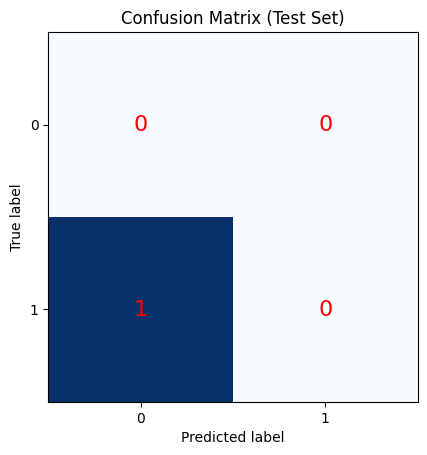

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6125 - auc: 0.4702 - loss: 0.7021 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7070 - auc: 0.5990 - loss: 0.6322 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7957 - auc: 0.6534 - loss: 0.5605 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8689 - auc: 0.7311 - loss: 0.4900 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8847 - auc: 0.7441 - loss: 0.4492 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9006 - auc: 0.7620 - loss: 0.3812 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9135 - auc: 0.7673 - loss: 0.3439 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9317 - auc: 0.7913 - loss: 0.2632 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9488 - auc: 0.7804 - loss: 0.2152 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9539 - auc: 0.7826 - loss: 0.1680 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
Test Prediction: 0.48 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


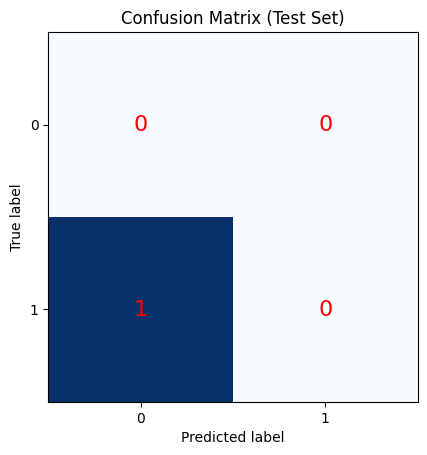

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6951 - auc: 0.5314 - loss: 0.6378 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7397 - auc: 0.6366 - loss: 0.5382 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9531 - auc: 0.0000e+00 - loss: 0.4012

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7922 - auc: 0.6868 - loss: 0.4794 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8509 - auc: 0.7521 - loss: 0.4313 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8774 - auc: 0.7576 - loss: 0.3725 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9009 - auc: 0.7731 - loss: 0.3272 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9191 - auc: 0.7806 - loss: 0.2745 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9242 - auc: 0.7980 - loss: 0.2129 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9449 - auc: 0.8006 - loss: 0.1751 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9568 - auc: 0.8040 - loss: 0.1399 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


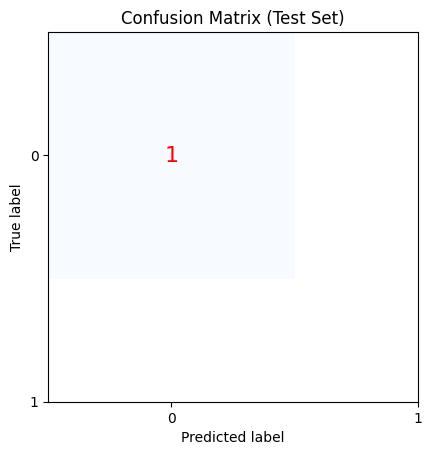

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5883 - auc: 0.4198 - loss: 0.7423 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6695 - auc: 0.5625 - loss: 0.6412 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7591 - auc: 0.6393 - loss: 0.5887 - learning_rate: 0.0010


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8127 - auc: 0.7225 - loss: 0.5324 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8553 - auc: 0.7553 - loss: 0.4822 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8798 - auc: 0.7470 - loss: 0.4655 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9240 - auc: 0.7825 - loss: 0.4148 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9128 - auc: 0.7932 - loss: 0.3646 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9368 - auc: 0.8030 - loss: 0.3188 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9401 - auc: 0.8035 - loss: 0.2579 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
Test Prediction: 0.44 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


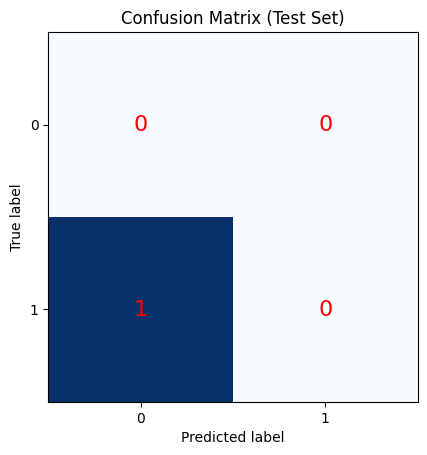

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6074 - auc: 0.5522 - loss: 0.6436 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7612 - auc: 0.6711 - loss: 0.5395 - learning_rate: 0.0010
Epoch 3/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8458 - auc: 0.7281 - loss: 0.4704 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8645 - auc: 0.7579 - loss: 0.4336 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8873 - auc: 0.7776 - loss: 0.3860 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9042 - auc: 0.7847 - loss: 0.3244 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9280 - auc: 0.7952 - loss: 0.2927 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9226 - auc: 0.8012 - loss: 0.2505 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9430 - auc: 0.8070 - loss: 0.1873 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9551 - auc: 0.8088 - loss: 0.1367 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/

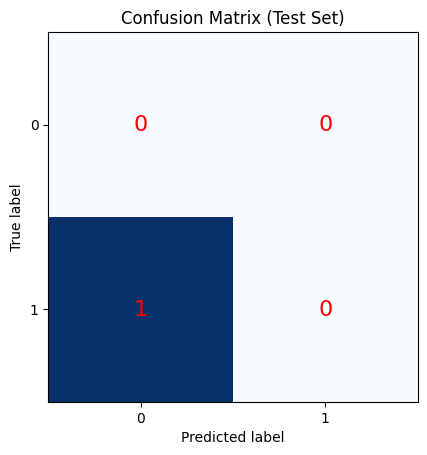

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2650 - auc: 0.2106 - loss: 0.9412 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4263 - auc: 0.3416 - loss: 0.8172 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4879 - auc: 0.4360 - loss: 0.7541 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5917 - auc: 0.5273 - loss: 0.6987 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6684 - auc: 0.6012 - loss: 0.6523 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7481 - auc: 0.6876 - loss: 0.5934 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7927 - auc: 0.7306 - loss: 0.5234 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8268 - auc: 0.7441 - loss: 0.4837 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8645 - auc: 0.7688 - loss: 0.4138 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8960 - auc: 0.7821 - loss: 0.3562 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
Test Prediction: 0.49 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


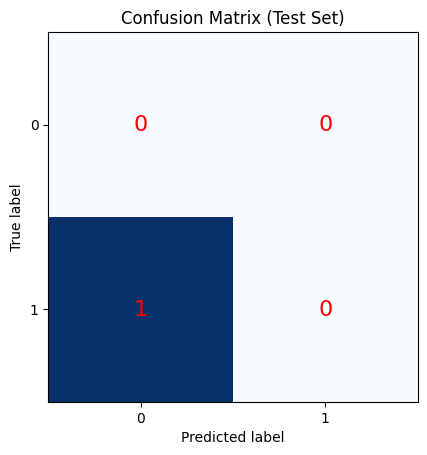

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5376 - auc: 0.3613 - loss: 0.7827 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6494 - auc: 0.5421 - loss: 0.6685 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6960 - auc: 0.6033 - loss: 0.6260 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7566 - auc: 0.6810 - loss: 0.5720 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8199 - auc: 0.7360 - loss: 0.5172 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8743 - auc: 0.7703 - loss: 0.4569 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8852 - auc: 0.7810 - loss: 0.4033 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8996 - auc: 0.7972 - loss: 0.3634 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9085 - auc: 0.7974 - loss: 0.3217 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9483 - auc: 0.8076 - loss: 0.2360 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Test Prediction: 0.48 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


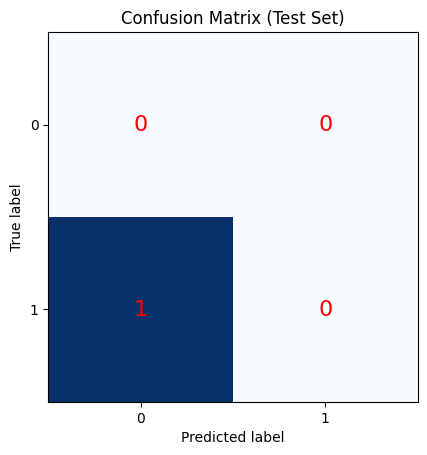

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3706 - auc: 0.2689 - loss: 0.9232 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5354 - auc: 0.3875 - loss: 0.7859 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6769 - auc: 0.5535 - loss: 0.6693 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7514 - auc: 0.6551 - loss: 0.5912 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8357 - auc: 0.7217 - loss: 0.5217 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8864 - auc: 0.7793 - loss: 0.4486 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9094 - auc: 0.7798 - loss: 0.3684 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9259 - auc: 0.7942 - loss: 0.2947 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9591 - auc: 0.8077 - loss: 0.2122 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9637 - auc: 0.8118 - loss: 0.1376 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Test Prediction: 0.49 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


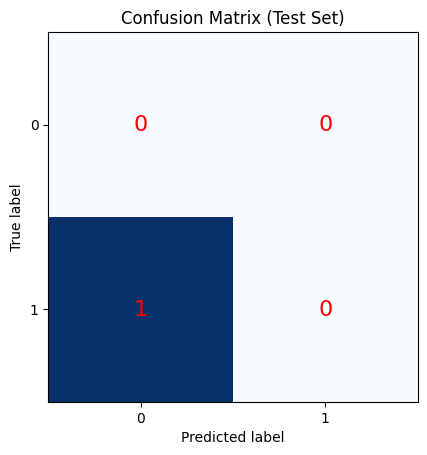

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5663 - auc: 0.4281 - loss: 0.6979 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6698 - auc: 0.6024 - loss: 0.5895 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6773 - auc: 0.6550 - loss: 0.5589 - learning_rate: 0.0010


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7777 - auc: 0.7421 - loss: 0.4714 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8076 - auc: 0.7621 - loss: 0.4283 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8317 - auc: 0.7878 - loss: 0.3584 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8915 - auc: 0.7976 - loss: 0.2875 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9185 - auc: 0.8042 - loss: 0.2190 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9322 - auc: 0.8094 - loss: 0.1647 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9393 - auc: 0.8082 - loss: 0.1367 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Test Prediction: 0.48 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


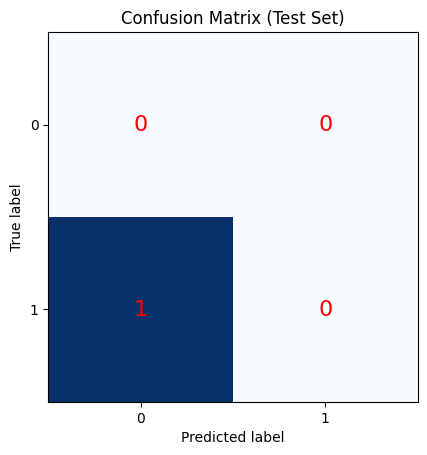

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2824 - auc: 0.2879 - loss: 1.0000 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4269 - auc: 0.3983 - loss: 0.8192 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5434 - auc: 0.4991 - loss: 0.7489 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6824 - auc: 0.6242 - loss: 0.6392 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8305 - auc: 0.7315 - loss: 0.5069 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8773 - auc: 0.7555 - loss: 0.4170 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8930 - auc: 0.7789 - loss: 0.3116 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9162 - auc: 0.7946 - loss: 0.2283 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9293 - auc: 0.8019 - loss: 0.1722 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9441 - auc: 0.8062 - loss: 0.1334 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Test Prediction: 0.53 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


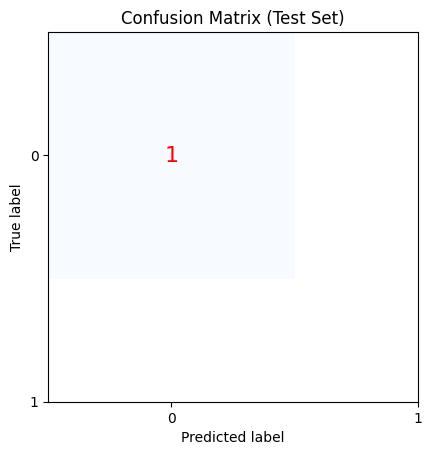

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3292 - auc: 0.3680 - loss: 0.8829 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4176 - auc: 0.4878 - loss: 0.8020 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4807 - auc: 0.5611 - loss: 0.7605 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5368 - auc: 0.6304 - loss: 0.7149 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5724 - auc: 0.7010 - loss: 0.6872 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6473 - auc: 0.7438 - loss: 0.6492 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7173 - auc: 0.7641 - loss: 0.6159 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7895 - auc: 0.7884 - loss: 0.5698 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8603 - auc: 0.7978 - loss: 0.5196 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9018 - auc: 0.8068 - loss: 0.4801 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
Test Prediction: 0.54 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


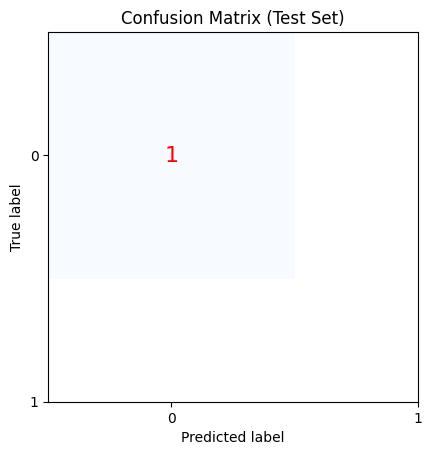

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3835 - auc: 0.3366 - loss: 1.0466 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4655 - auc: 0.4938 - loss: 0.8709 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.1562 - auc: 0.0000e+00 - loss: 1.1877

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5288 - auc: 0.5935 - loss: 0.7787 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5740 - auc: 0.6260 - loss: 0.7177 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6662 - auc: 0.6933 - loss: 0.6385 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7152 - auc: 0.7152 - loss: 0.5754 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8081 - auc: 0.7344 - loss: 0.5088 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8615 - auc: 0.7717 - loss: 0.4231 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8954 - auc: 0.7846 - loss: 0.3477 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9153 - auc: 0.7927 - loss: 0.3053 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


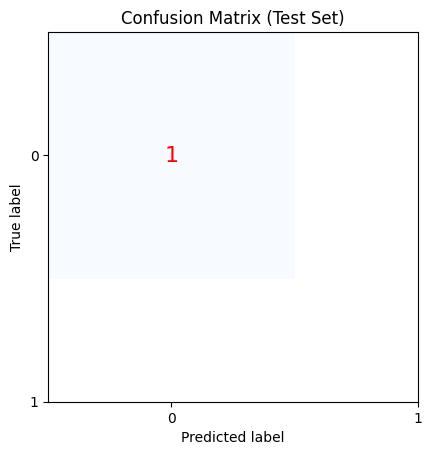

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6426 - auc: 0.5016 - loss: 0.6759 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7199 - auc: 0.6550 - loss: 0.5729 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7687 - auc: 0.7120 - loss: 0.5212 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8282 - auc: 0.7347 - loss: 0.4790 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8548 - auc: 0.7566 - loss: 0.4411 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8717 - auc: 0.7786 - loss: 0.3884 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8863 - auc: 0.7755 - loss: 0.3552 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9106 - auc: 0.7866 - loss: 0.2987 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9177 - auc: 0.7910 - loss: 0.2623 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9208 - auc: 0.8014 - loss: 0.1969 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
Test Prediction: 0.50 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


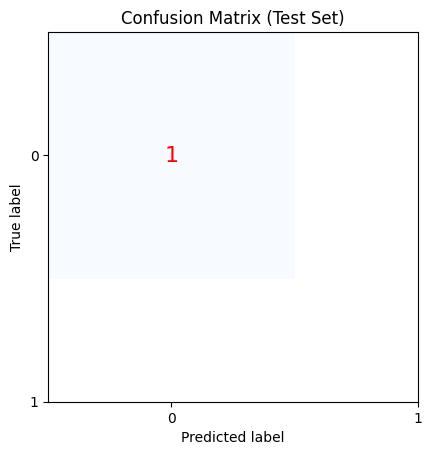

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6615 - auc: 0.5045 - loss: 0.6591 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7500 - auc: 0.6391 - loss: 0.5703 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8176 - auc: 0.6971 - loss: 0.5246 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8450 - auc: 0.7327 - loss: 0.4695 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8990 - auc: 0.7670 - loss: 0.3862 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8914 - auc: 0.7689 - loss: 0.3470 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8889 - auc: 0.7868 - loss: 0.2898 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9095 - auc: 0.7912 - loss: 0.2491 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9263 - auc: 0.8023 - loss: 0.1776 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9244 - auc: 0.8020 - loss: 0.1484 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Test Prediction: 0.53 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


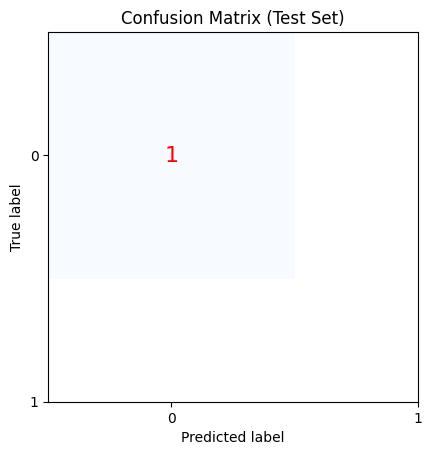

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6587 - auc: 0.4728 - loss: 0.7062 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7289 - auc: 0.6241 - loss: 0.6046 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7854 - auc: 0.6627 - loss: 0.5728 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8188 - auc: 0.7056 - loss: 0.5214 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8146 - auc: 0.7130 - loss: 0.5128 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8346 - auc: 0.7341 - loss: 0.4702 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8728 - auc: 0.7589 - loss: 0.4284 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9103 - auc: 0.7922 - loss: 0.3574 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9099 - auc: 0.7833 - loss: 0.3355 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9201 - auc: 0.7894 - loss: 0.2874 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Test Prediction: 0.50 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


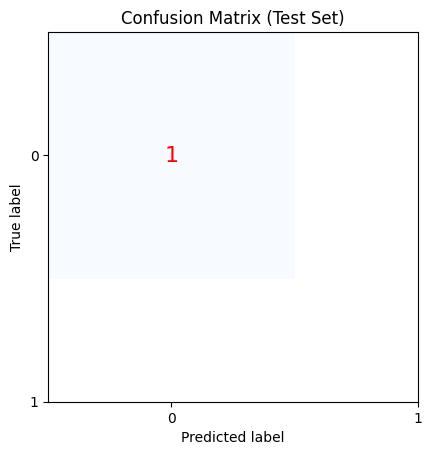

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5925 - auc: 0.4835 - loss: 0.7257 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7489 - auc: 0.6364 - loss: 0.6159 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7793 - auc: 0.6919 - loss: 0.5692 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8218 - auc: 0.7265 - loss: 0.5252 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8576 - auc: 0.7548 - loss: 0.4812 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8949 - auc: 0.7732 - loss: 0.4148 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9185 - auc: 0.7952 - loss: 0.3555 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9307 - auc: 0.7990 - loss: 0.3162 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9251 - auc: 0.7982 - loss: 0.2684 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9338 - auc: 0.8036 - loss: 0.2146 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Test Prediction: 0.49 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


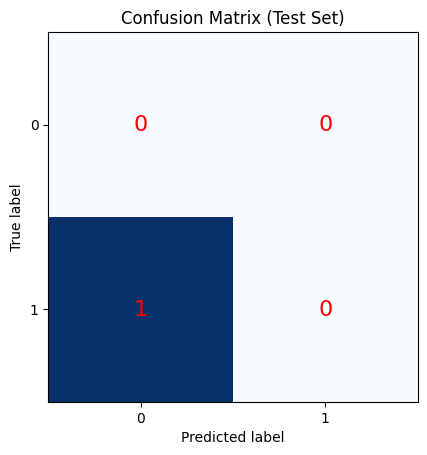

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3298 - auc: 0.2011 - loss: 1.0030 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4614 - auc: 0.3628 - loss: 0.8070 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5857 - auc: 0.5336 - loss: 0.7000 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7209 - auc: 0.6325 - loss: 0.6261 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7213 - auc: 0.6479 - loss: 0.6092 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8090 - auc: 0.7198 - loss: 0.5320 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8548 - auc: 0.7461 - loss: 0.4621 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8800 - auc: 0.7635 - loss: 0.4333 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9186 - auc: 0.7906 - loss: 0.3425 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9188 - auc: 0.7899 - loss: 0.2995 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
Test Prediction: 0.38 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


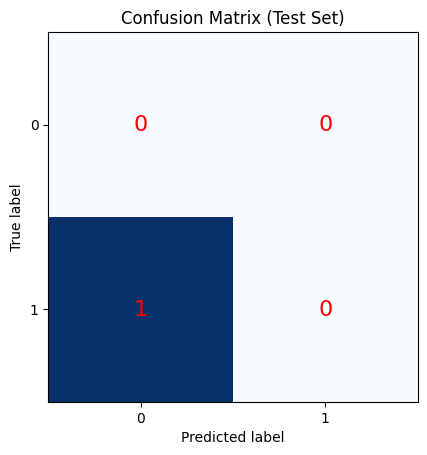

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5398 - auc: 0.3496 - loss: 0.7768 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6683 - auc: 0.4980 - loss: 0.6696 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9219 - auc: 0.0000e+00 - loss: 0.6470

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7166 - auc: 0.5894 - loss: 0.6163 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7936 - auc: 0.6814 - loss: 0.5573 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8278 - auc: 0.7265 - loss: 0.4905 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8739 - auc: 0.7616 - loss: 0.4243 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8864 - auc: 0.7745 - loss: 0.3615 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8963 - auc: 0.7788 - loss: 0.3044 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9263 - auc: 0.8010 - loss: 0.2078 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9442 - auc: 0.8062 - loss: 0.1523 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/

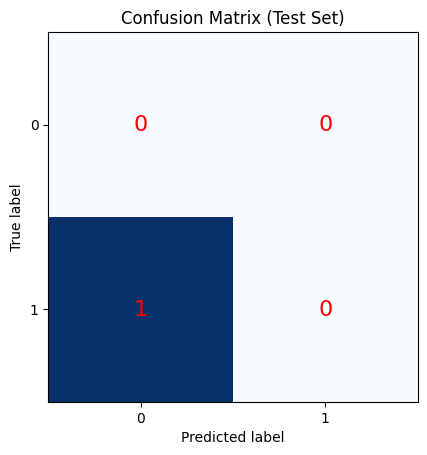

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4129 - auc: 0.3636 - loss: 0.8389 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6302 - auc: 0.5391 - loss: 0.6950 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7106 - auc: 0.6107 - loss: 0.6505 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7701 - auc: 0.6778 - loss: 0.6037 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8175 - auc: 0.7284 - loss: 0.5447 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8156 - auc: 0.7518 - loss: 0.5175 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8591 - auc: 0.7688 - loss: 0.4695 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8845 - auc: 0.7906 - loss: 0.4241 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9033 - auc: 0.7941 - loss: 0.3606 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9167 - auc: 0.7989 - loss: 0.3271 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Test Prediction: 0.51 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


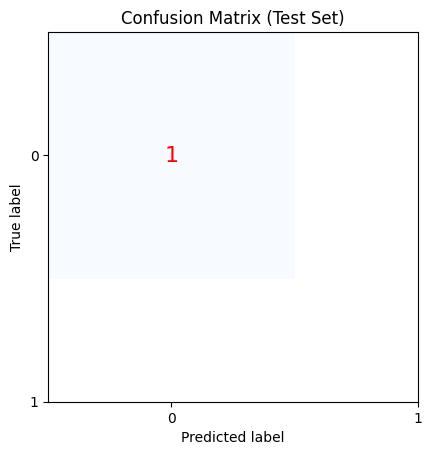

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3225 - auc: 0.2060 - loss: 0.8639 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4960 - auc: 0.3606 - loss: 0.7776 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5737 - auc: 0.4849 - loss: 0.7324 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7362 - auc: 0.6525 - loss: 0.6547 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8273 - auc: 0.7260 - loss: 0.5827 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8502 - auc: 0.7472 - loss: 0.5147 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9288 - auc: 0.7916 - loss: 0.3785 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9095 - auc: 0.7936 - loss: 0.3230 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9374 - auc: 0.8062 - loss: 0.1989 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9624 - auc: 0.8083 - loss: 0.1541 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
Test Prediction: 0.57 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


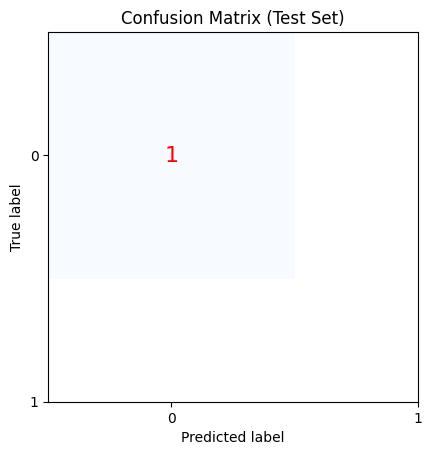

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5526 - auc: 0.4063 - loss: 0.7318 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6101 - auc: 0.5075 - loss: 0.6498 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9531 - auc: 0.0000e+00 - loss: 0.3610

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6502 - auc: 0.5708 - loss: 0.5937 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6979 - auc: 0.6442 - loss: 0.5495 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7607 - auc: 0.6908 - loss: 0.5034 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7819 - auc: 0.7163 - loss: 0.4653 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7873 - auc: 0.7370 - loss: 0.4213 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8209 - auc: 0.7509 - loss: 0.3827 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8508 - auc: 0.7606 - loss: 0.3408 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8481 - auc: 0.7738 - loss: 0.2911 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/

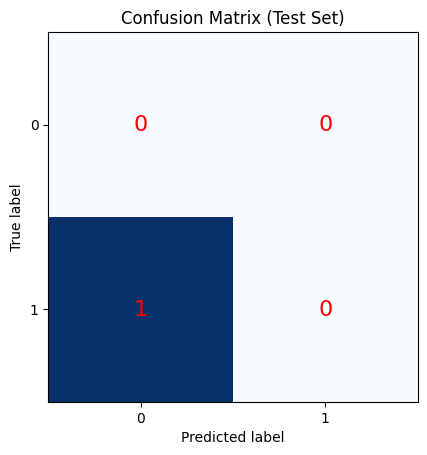

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4846 - auc: 0.3763 - loss: 0.7984 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6176 - auc: 0.5285 - loss: 0.7170 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7089 - auc: 0.6394 - loss: 0.6605 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7775 - auc: 0.6997 - loss: 0.6090 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8273 - auc: 0.7357 - loss: 0.5637 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8572 - auc: 0.7648 - loss: 0.5314 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8749 - auc: 0.7770 - loss: 0.4672 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8996 - auc: 0.7871 - loss: 0.4249 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9076 - auc: 0.7892 - loss: 0.3850 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9295 - auc: 0.8006 - loss: 0.3005 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
Test Prediction: 0.52 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


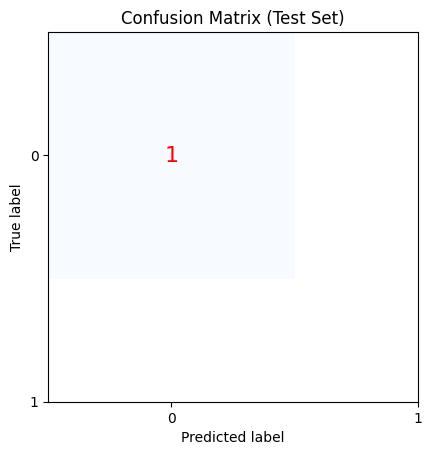

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2531 - auc: 0.1802 - loss: 0.9802 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3630 - auc: 0.2931 - loss: 0.8743 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5200 - auc: 0.4728 - loss: 0.7817 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5766 - auc: 0.5927 - loss: 0.7363 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6768 - auc: 0.6738 - loss: 0.6793 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7539 - auc: 0.7411 - loss: 0.6114 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7799 - auc: 0.7663 - loss: 0.5595 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8610 - auc: 0.7959 - loss: 0.4874 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9093 - auc: 0.8038 - loss: 0.4342 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9053 - auc: 0.7942 - loss: 0.3941 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
Test Prediction: 0.52 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


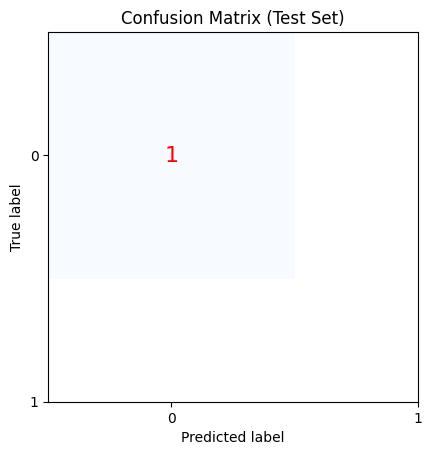

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5176 - auc: 0.4011 - loss: 0.7664 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6776 - auc: 0.5974 - loss: 0.6631 - learning_rate: 0.0010
Epoch 3/74
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9375 - auc: 0.0000e+00 - loss: 0.6627

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7782 - auc: 0.6808 - loss: 0.6189 - learning_rate: 0.0010
Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8199 - auc: 0.7299 - loss: 0.5692 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8581 - auc: 0.7471 - loss: 0.5423 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8656 - auc: 0.7559 - loss: 0.4971 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9101 - auc: 0.7852 - loss: 0.4142 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9212 - auc: 0.7892 - loss: 0.3770 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9147 - auc: 0.7917 - loss: 0.3205 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9501 - auc: 0.8016 - loss: 0.2456 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


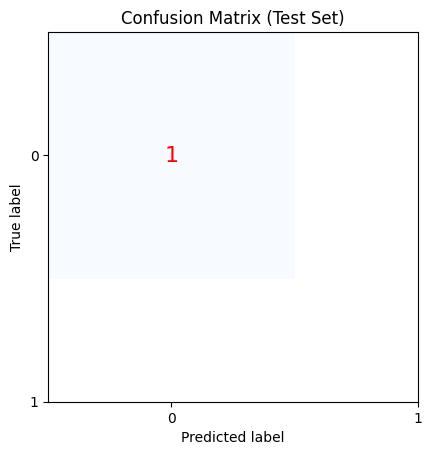

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5924 - auc: 0.5451 - loss: 0.6690 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6688 - auc: 0.6505 - loss: 0.5643 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7347 - auc: 0.6831 - loss: 0.5387 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8105 - auc: 0.7288 - loss: 0.5009 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8317 - auc: 0.7542 - loss: 0.4486 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8564 - auc: 0.7605 - loss: 0.4102 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8626 - auc: 0.7701 - loss: 0.3770 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9036 - auc: 0.7891 - loss: 0.3207 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9125 - auc: 0.7920 - loss: 0.2689 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9422 - auc: 0.8028 - loss: 0.2132 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
Test Prediction: 0.52 (Class: 1)
Confusion Matrix:
[[1]]
TN: 0, FP: 0, FN: 0, TP: 0


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


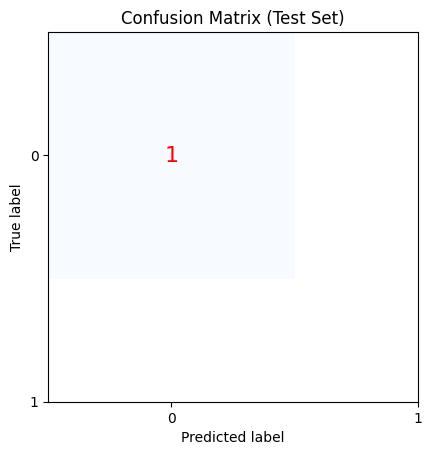

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2919 - auc: 0.1707 - loss: 1.2104 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3731 - auc: 0.3006 - loss: 1.0105 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4090 - auc: 0.4429 - loss: 0.9419 - learning_rate: 0.0010
Epoch 4/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4342 - auc: 0.5126 - loss: 0.8876 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4628 - auc: 0.6137 - loss: 0.8173 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5139 - auc: 0.6646 - loss: 0.7653 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6001 - auc: 0.6990 - loss: 0.7113 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6388 - auc: 0.7540 - loss: 0.6629 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7336 - auc: 0.7728 - loss: 0.5902 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7511 - auc: 0.7722 - loss: 0.5612 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
Test Prediction: 0.48 (Class: 0)
Confusion Matrix:
[[0 0]
 [1 0]]
TN: 0, FP: 0, FN: 1, TP: 0


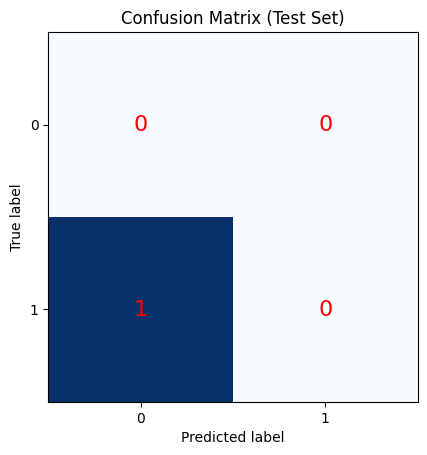

Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


In [16]:
# Train and evaluate the model with sliding window
for start in range(start_point, len(X_scaled) - window_size, step_size):
    try:
        end = start + window_size
        X_train_window = X_scaled[start:end]
        y_train_window = y[start:end]
        
        # Define test indices
        test_start = end
        test_end = test_start + 1
        if test_end > len(X_scaled):
            break
        X_test_window = X_scaled[test_start:test_end]
        y_test_window = y[test_start:test_end]

        # Sequence length for training
        seqlen = 10
        # Number of features
        numfeat = X_train_window.shape[1]

        # Generate sequence input for the training dataset
        train_generator = TimeseriesGenerator(X_train_window, y_train_window, length=seqlen, batch_size=64)

        # Calculate custom class weights using y_train_window
        class_weight = cwts(y_train_window)

        # Create a new model for each window
        model = create_model(hu=20, lookback=10, features=numfeat)

        model.fit(train_generator, epochs=74, verbose=1, class_weight=class_weight, shuffle=False, callbacks=[early_stopping, reduce_lr])

        # Predict on the single test sample directly
        test_input = np.expand_dims(X_test_window, axis=0)
        prediction = model.predict(test_input)
        prediction_probability = prediction[0][0]
        predicted_class = int(prediction_probability > 0.5)
        print(f'Test Prediction: {prediction_probability:.2f} (Class: {predicted_class})')

        # Store test predictions, actual values, and predicted classes
        all_test_predictions.append(predicted_class)
        all_actual_test_values.append(y_test_window[0])
        all_prediction_probabilities.append(prediction_probability)
        all_predicted_classes.append(predicted_class)
        all_predicted_probabilities.append(prediction_probability)

        # Calculate and print confusion matrix for each window
        cm = confusion_matrix([y_test_window[0]], [predicted_class])
        print(f'Confusion Matrix:\n{cm}')
        
        # Extract counts from confusion matrix
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        print(f'TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}')

        # Plot the confusion matrix for each window
        fig, ax = plt.subplots()
        ax.imshow(cm, cmap=plt.cm.Blues)
        ax.grid(False)

        for i in range(cm.shape[0]):  # Add number annotations for each cell
            for j in range(cm.shape[1]):
                ax.text(j, i, cm[i, j], ha="center", va="center", color="red", fontsize=16)

        plt.title('Confusion Matrix (Test Set)')
        plt.xlabel('Predicted label')
        plt.ylabel('True label')
        plt.xticks(np.arange(2), [0, 1])
        plt.yticks(np.arange(2), [0, 1])

        plt.show()

    except Exception as e:
        print(f'Error at window {start} to {end}: {e}')
        break

In [ ]:
# Save the results to files for further analysis
results = {
    "predicted_classes": all_test_predictions,
    "actual_test_values": all_actual_test_values,
    "prediction_probabilities": all_prediction_probabilities,
    "predicted_probabilities": all_predicted_probabilities
}

results_df = pd.DataFrame(results)
results_df.to_csv('SL_1_results_CMA.csv', index=False)


In [ ]:
# Generate and print the combined classification report
combined_classification_report = classification_report(all_actual_test_values, all_predicted_classes, output_dict=True)
print("Combined Classification Report:")
print(combined_classification_report)

Combined Classification Report:
{'accuracy': 0.0, 'macro avg': {'precision': nan, 'recall': nan, 'f1-score': nan, 'support': 0.0}, 'weighted avg': {'precision': nan, 'recall': nan, 'f1-score': nan, 'support': 0.0}}


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

In [ ]:
# Calculate and print the combined confusion matrix
combined_cm = confusion_matrix(all_actual_test_values, all_predicted_classes)
print(f'Combined Confusion Matrix:\n{combined_cm}')


Combined Confusion Matrix:
[]


C:\Users\tonfo\AppData\Local\Temp\ipykernel_53692\582502835.py:3: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.imshow(combined_cm, cmap=plt.cm.Blues)
C:\Users\tonfo\AppData\Local\Temp\ipykernel_53692\582502835.py:3: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.imshow(combined_cm, cmap=plt.cm.Blues)


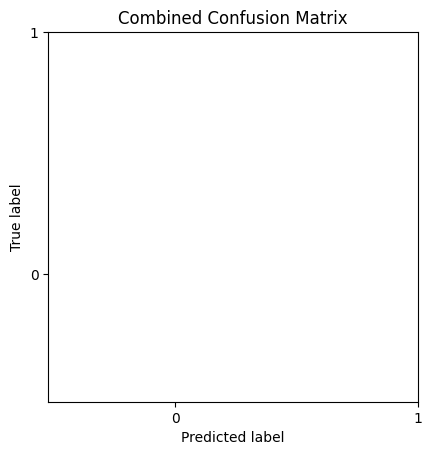

In [ ]:
# Plot the combined confusion matrix
fig, ax = plt.subplots()
ax.imshow(combined_cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(combined_cm.shape[0]):  # Add number annotations for each cell
    for j in range(combined_cm.shape[1]):
        ax.text(j, i, combined_cm[i, j], ha="center", va="center", color="red", fontsize=16)

plt.title('Combined Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()


In [ ]:
# Save the final model
model.save('SL_1_model_CMA.h5')